# CyberSentry — 03 · ML Anomaly Detection (Stage 1: Normal vs Suspicious)

**Goal:** decide for every network flow whether it is **Normal (0)** or **Suspicious (1)**. Flows flagged here are passed to the DL stage, which identifies the attack type.

**Input:** `data/processed/train|val|test.parquet` and `models/preprocessing/` (from notebook 02)

We compare two families of models:

| Family | Models | Trained on | Idea |
|---|---|---|---|
| **Unsupervised** (anomaly detection) | Isolation Forest, One-Class SVM | BENIGN traffic only | Learn what "normal" looks like; anything different is suspicious. Can catch attacks never seen before. |
| **Supervised** (classification) | Random Forest, XGBoost | Labelled BENIGN + attacks | Learn the difference between normal and known attacks directly. Usually more accurate on known attack types. |

**Evaluation** (on the held-out test set, used only once): accuracy, precision, recall (detection rate), F1, ROC-AUC, false positive rate (FPR), false negative rate (FNR), confusion matrices, training/prediction time.

**Model selection** is done on the **validation** set, so the test set stays untouched until the final report.

## 1. Setup

In [1]:
import json
import time
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import IsolationForest, RandomForestClassifier
from sklearn.svm import OneClassSVM
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, roc_curve, precision_recall_curve,
                             ConfusionMatrixDisplay)
from xgboost import XGBClassifier

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 140)
SEED = 42

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
PROC_DIR = ROOT / "data" / "processed"
PRE_DIR = ROOT / "models" / "preprocessing"
ML_DIR = ROOT / "models" / "ml"
ML_DIR.mkdir(parents=True, exist_ok=True)

meta = json.load(open(PRE_DIR / "selected_features.json"))
FEATURES = meta["selected_features"]
scaler = joblib.load(PRE_DIR / "scaler.joblib")

train = pd.read_parquet(PROC_DIR / "train.parquet")
val = pd.read_parquet(PROC_DIR / "val.parquet")
test = pd.read_parquet(PROC_DIR / "test.parquet")

X_train, y_train = train[FEATURES], train["binary_label"].values
X_val, y_val = val[FEATURES], val["binary_label"].values
X_test, y_test = test[FEATURES], test["binary_label"].values

print(f"{len(FEATURES)} features")
for name, y in [("train", y_train), ("val", y_val), ("test", y_test)]:
    print(f"{name:<5} {len(y):>9,} rows | attacks: {y.mean():.2%}")

32 features
train 1,748,729 rows | attacks: 17.04%
val     374,728 rows | attacks: 17.04%
test    374,728 rows | attacks: 17.04%


## 2. Evaluation helpers

`evaluate()` computes every metric we report. **FPR** (normal traffic wrongly flagged) matters a lot in a real SOC because every false alarm costs analyst time; **FNR** (attacks missed) is the dangerous one.

For the unsupervised models, the decision **threshold** on the anomaly score is chosen on the validation set (the value that maximises F1). This is standard practice and is documented as such.

In [2]:
results = {}      # model name -> metrics on TEST
val_scores = {}   # model name -> F1 on VALIDATION (used for model selection)
test_outputs = {} # model name -> (scores, predictions) on TEST, for plots

def evaluate(name, y_true, y_pred, y_score, train_time, pred_time):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall (DR)": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, y_score),
        "FPR": fp / (fp + tn),
        "FNR": fn / (fn + tp),
        "Train time (s)": train_time,
        "Predict time (s)": pred_time,
    }

def best_threshold(y_true, scores):
    """Threshold on an anomaly score (higher = more suspicious) that maximises F1."""
    p, r, t = precision_recall_curve(y_true, scores)
    f1 = 2 * p * r / np.clip(p + r, 1e-12, None)
    return t[np.argmax(f1[:-1])]

def record(name, model_val_scores, model_test_scores, threshold, train_time, pred_time):
    val_pred = (model_val_scores >= threshold).astype(int)
    test_pred = (model_test_scores >= threshold).astype(int)
    val_scores[name] = f1_score(y_val, val_pred)
    results[name] = evaluate(name, y_test, test_pred, model_test_scores, train_time, pred_time)
    test_outputs[name] = (model_test_scores, test_pred)
    print(f"{name}: val F1 = {val_scores[name]:.4f} | test F1 = {results[name]['F1']:.4f} "
          f"| test recall = {results[name]['Recall (DR)']:.4f} | test FPR = {results[name]['FPR']:.4f}")

## 3. Unsupervised models (trained on BENIGN traffic only)

### 3.1 Isolation Forest
Builds random trees; unusual points get isolated in fewer splits. Trained on a 200k sample of BENIGN training flows (Isolation Forest works on small samples by design).

In [3]:
benign_train = X_train[y_train == 0]
if_sample = benign_train.sample(min(200_000, len(benign_train)), random_state=SEED)

t0 = time.time()
iso = IsolationForest(n_estimators=200, max_samples=256, contamination="auto", n_jobs=-1, random_state=SEED)
iso.fit(if_sample)
train_time = time.time() - t0

# score_samples: higher = more normal, so negate to get "higher = more suspicious"
iso_val = -iso.score_samples(X_val)
t0 = time.time(); iso_test = -iso.score_samples(X_test); pred_time = time.time() - t0
record("Isolation Forest", iso_val, iso_test, best_threshold(y_val, iso_val), train_time, pred_time)

Isolation Forest: val F1 = 0.5674 | test F1 = 0.5670 | test recall = 0.5879 | test FPR = 0.0998


### 3.2 One-Class SVM
Learns a boundary around normal traffic in a high-dimensional space. It scales poorly (training time grows roughly with the square of the number of rows), so it is trained on a 20k sample of **scaled** BENIGN flows. This limitation is itself a finding worth reporting.

In [4]:
ocsvm_sample = scaler.transform(benign_train.sample(min(20_000, len(benign_train)), random_state=SEED).astype(np.float64))
Xs_val = scaler.transform(X_val.astype(np.float64))
Xs_test = scaler.transform(X_test.astype(np.float64))

t0 = time.time()
ocsvm = OneClassSVM(kernel="rbf", gamma="scale", nu=0.05)
ocsvm.fit(ocsvm_sample)
train_time = time.time() - t0

oc_val = -ocsvm.decision_function(Xs_val)
t0 = time.time(); oc_test = -ocsvm.decision_function(Xs_test); pred_time = time.time() - t0
record("One-Class SVM", oc_val, oc_test, best_threshold(y_val, oc_val), train_time, pred_time)

One-Class SVM: val F1 = 0.6495 | test F1 = 0.6488 | test recall = 0.5607 | test FPR = 0.0345


## 4. Supervised models (trained on labelled data)

### 4.1 Random Forest
`class_weight="balanced_subsample"` gives the minority (attack) class more weight. Each tree sees 30% of the training rows (`max_samples=0.3`) to keep training time reasonable on a laptop.

In [5]:
t0 = time.time()
rf = RandomForestClassifier(n_estimators=100, max_samples=0.3, class_weight="balanced_subsample",
                            n_jobs=-1, random_state=SEED)
rf.fit(X_train, y_train)
train_time = time.time() - t0

rf_val = rf.predict_proba(X_val)[:, 1]
t0 = time.time(); rf_test = rf.predict_proba(X_test)[:, 1]; pred_time = time.time() - t0
record("Random Forest", rf_val, rf_test, 0.5, train_time, pred_time)

Random Forest: val F1 = 0.9970 | test F1 = 0.9972 | test recall = 0.9978 | test FPR = 0.0007


### 4.2 XGBoost
Gradient-boosted trees. `scale_pos_weight` corrects for the class imbalance, and **early stopping** on the validation set stops training when it no longer improves.

In [6]:
def train_xgb(Xtr, ytr, Xva, yva):
    model = XGBClassifier(n_estimators=500, learning_rate=0.1, max_depth=8, tree_method="hist",
                          scale_pos_weight=(ytr == 0).sum() / max((ytr == 1).sum(), 1),
                          eval_metric="logloss", early_stopping_rounds=20,
                          n_jobs=-1, random_state=SEED)
    model.fit(Xtr, ytr, eval_set=[(Xva, yva)], verbose=False)
    return model

t0 = time.time()
xgb = train_xgb(X_train, y_train, X_val, y_val)
train_time = time.time() - t0
print("Best iteration:", xgb.best_iteration)

xgb_val = xgb.predict_proba(X_val)[:, 1]
t0 = time.time(); xgb_test = xgb.predict_proba(X_test)[:, 1]; pred_time = time.time() - t0
record("XGBoost", xgb_val, xgb_test, 0.5, train_time, pred_time)

Best iteration: 351
XGBoost: val F1 = 0.9973 | test F1 = 0.9975 | test recall = 0.9996 | test FPR = 0.0009


## 5. Comparison on the test set

In [7]:
comparison = pd.DataFrame(results).T
comparison.insert(0, "Val F1", pd.Series(val_scores))
comparison = comparison.sort_values("Val F1", ascending=False)
comparison.style.format({c: "{:.4f}" for c in comparison.columns if "time" not in c}
                        | {c: "{:.1f}" for c in comparison.columns if "time" in c}) \
                .highlight_max(subset=["Val F1", "Accuracy", "Precision", "Recall (DR)", "F1", "ROC-AUC"], color="#2a6f4a") \
                .highlight_min(subset=["FPR", "FNR"], color="#2a6f4a")

,Val F1,Accuracy,Precision,Recall (DR),F1,ROC-AUC,FPR,FNR,Train time (s),Predict time (s)
XGBoost,0.9973,0.9992,0.9954,0.9996,0.9975,1.0000,0.0009,0.0004,28.6,0.4
Random Forest,0.9970,0.9991,0.9967,0.9978,0.9972,0.9998,0.0007,0.0022,29.6,0.3
One-Class SVM,0.6495,0.8966,0.7698,0.5607,0.6488,0.8068,0.0345,0.4393,1.7,24.6
Isolation Forest,0.5674,0.8470,0.5475,0.5879,0.5670,0.8169,0.0998,0.4121,1.0,4.6


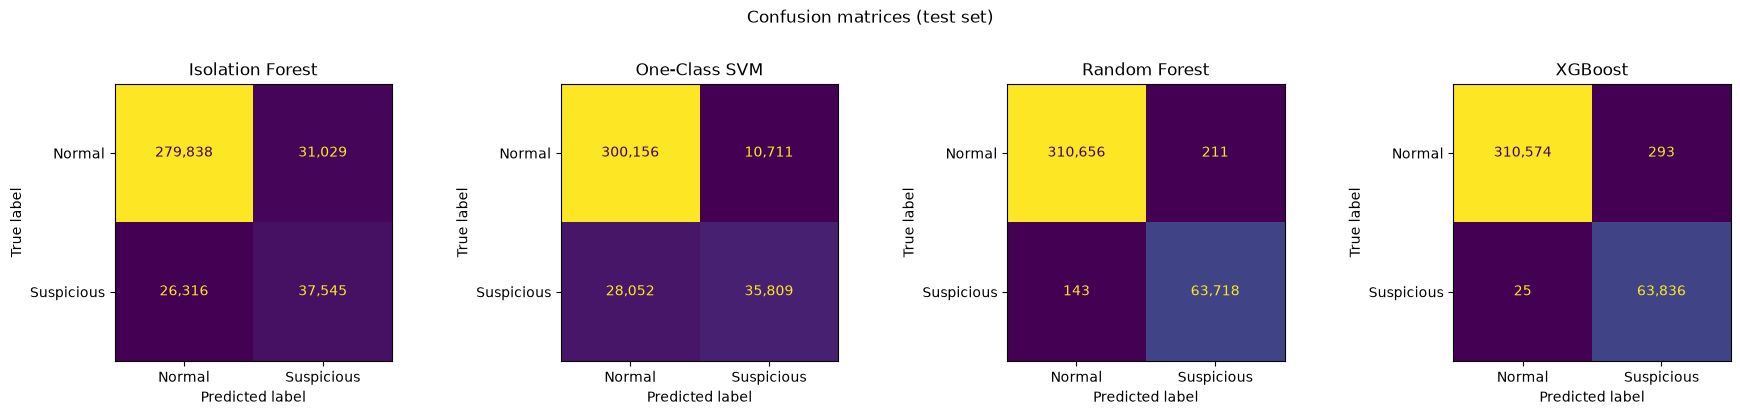

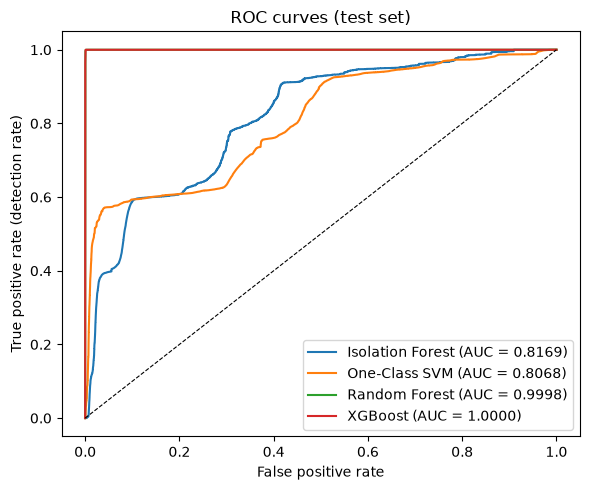

In [8]:
fig, axes = plt.subplots(1, len(test_outputs), figsize=(4.5 * len(test_outputs), 4))
for ax, (name, (_, pred)) in zip(np.atleast_1d(axes), test_outputs.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred, labels=[0, 1]),
                           display_labels=["Normal", "Suspicious"]).plot(ax=ax, colorbar=False, values_format=",")
    ax.set_title(name)
plt.suptitle("Confusion matrices (test set)", y=1.02); plt.tight_layout(); plt.show()

plt.figure(figsize=(6, 5))
for name, (scores, _) in test_outputs.items():
    fpr, tpr, _ = roc_curve(y_test, scores)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {results[name]['ROC-AUC']:.4f})")
plt.plot([0, 1], [0, 1], "k--", lw=0.8)
plt.xlabel("False positive rate"); plt.ylabel("True positive rate (detection rate)")
plt.title("ROC curves (test set)"); plt.legend(); plt.tight_layout(); plt.show()

## 6. Which attacks does each model catch?

Overall recall hides a lot. Here is the **detection rate per attack type**: the share of each attack's flows flagged as suspicious. This shows, for example, whether the unsupervised models miss stealthy attacks that look like normal traffic.

In [9]:
per_attack = {}
for name, (_, pred) in test_outputs.items():
    per_attack[name] = pd.Series(pred).groupby(test["Label"].values).mean()
per_attack = pd.DataFrame(per_attack)
per_attack.insert(0, "Test rows", test["Label"].value_counts())
per_attack = per_attack.sort_values("Test rows", ascending=False)
per_attack = per_attack.rename(index={"BENIGN": "BENIGN (false alarm rate)"})
per_attack.style.format({c: "{:.2%}" for c in per_attack.columns if c != "Test rows"} | {"Test rows": "{:,}"})

,Test rows,Isolation Forest,One-Class SVM,Random Forest,XGBoost
BENIGN (false alarm rate),"310,867",9.98%,3.45%,0.07%,0.09%
DoS Hulk,"25,927",90.30%,86.23%,99.83%,100.00%
DDoS,"19,202",60.91%,58.68%,99.97%,99.99%
PortScan,"13,604",0.57%,2.28%,99.96%,99.99%
DoS GoldenEye,"1,543",80.88%,48.80%,99.94%,100.00%
FTP-Patator,890,0.00%,0.00%,100.00%,100.00%
DoS slowloris,808,59.16%,58.66%,99.75%,100.00%
DoS Slowhttptest,784,77.42%,80.48%,99.49%,99.74%
SSH-Patator,483,0.21%,0.21%,99.79%,100.00%
Bot,292,1.71%,3.08%,77.40%,94.18%


## 7. Shortcut check: does the model rely on dataset artifacts?

In CIC-IDS2017 each attack targets specific ports (FTP-Patator → 21, SSH-Patator → 22, most DoS/web attacks → 80), and attack tools often use fixed TCP window sizes. A model can score highly by memorising **"port 21 = attack"** instead of learning attack behaviour, and that would not generalise to a real network.

We retrain the best supervised model **without** `Destination Port` and the `Init_Win_bytes_*` features. A small drop means the model learned genuine traffic behaviour.

In [10]:
SHORTCUT_FEATURES = [f for f in ["Destination Port", "Init_Win_bytes_forward", "Init_Win_bytes_backward"] if f in FEATURES]
REDUCED = [f for f in FEATURES if f not in SHORTCUT_FEATURES]
print("Removed:", SHORTCUT_FEATURES, f"-> {len(REDUCED)} features left")

t0 = time.time()
xgb_reduced = train_xgb(X_train[REDUCED], y_train, X_val[REDUCED], y_val)
train_time = time.time() - t0
red_val = xgb_reduced.predict_proba(X_val[REDUCED])[:, 1]
t0 = time.time(); red_test = xgb_reduced.predict_proba(X_test[REDUCED])[:, 1]; pred_time = time.time() - t0
record("XGBoost (no port/window)", red_val, red_test, 0.5, train_time, pred_time)

ablation = pd.DataFrame(results).T.loc[["XGBoost", "XGBoost (no port/window)"],
                                       ["Precision", "Recall (DR)", "F1", "ROC-AUC", "FPR", "FNR"]]
ablation.loc["Change"] = ablation.iloc[1] - ablation.iloc[0]
ablation.style.format("{:.4f}")

Removed: ['Destination Port', 'Init_Win_bytes_forward', 'Init_Win_bytes_backward'] -> 29 features left
XGBoost (no port/window): val F1 = 0.9922 | test F1 = 0.9925 | test recall = 0.9940 | test FPR = 0.0018


,Precision,Recall (DR),F1,ROC-AUC,FPR,FNR
XGBoost,0.9954,0.9996,0.9975,1.0000,0.0009,0.0004
XGBoost (no port/window),0.9911,0.9940,0.9925,0.9998,0.0018,0.0060
Change,-0.0044,-0.0056,-0.0050,-0.0002,0.0009,0.0056


## 8. Select and save the Stage-1 model

The model is chosen by **validation F1** (not test), among all models trained above. If the version without port/window features is within 0.5% F1 of the best, we prefer it because it is more likely to generalise to real traffic.

In [11]:
saved_models = {"Isolation Forest": iso, "One-Class SVM": ocsvm, "Random Forest": rf,
                "XGBoost": xgb, "XGBoost (no port/window)": xgb_reduced}
feature_sets = {"XGBoost (no port/window)": REDUCED}
thresholds = {"Isolation Forest": float(best_threshold(y_val, iso_val)),
              "One-Class SVM": float(best_threshold(y_val, oc_val))}

ranked = pd.Series(val_scores).sort_values(ascending=False)
best = ranked.index[0]
if best != "XGBoost (no port/window)" and ranked[best] - ranked["XGBoost (no port/window)"] <= 0.005:
    best = "XGBoost (no port/window)"
print("Validation F1 ranking:\n" + ranked.round(4).to_string())
print(f"\nSelected Stage-1 model: {best}")

joblib.dump(saved_models[best], ML_DIR / "stage1_model.joblib")
stage1_meta = {
    "model": best,
    "features": feature_sets.get(best, FEATURES),
    "needs_scaling": best == "One-Class SVM",
    "score": "higher = more suspicious",
    "threshold": thresholds.get(best, 0.5),
    "val_f1": float(val_scores[best]),
    "test_metrics": {k: float(v) for k, v in results[best].items()},
}
json.dump(stage1_meta, open(ML_DIR / "stage1_meta.json", "w"), indent=2)
comparison_out = pd.DataFrame(results).T
comparison_out.insert(0, "Val F1", pd.Series(val_scores))
comparison_out.to_csv(ML_DIR / "ml_comparison.csv")
print("Saved model, metadata and comparison table to", ML_DIR)

Validation F1 ranking:
XGBoost                     0.9973
Random Forest               0.9970
XGBoost (no port/window)    0.9922
One-Class SVM               0.6495
Isolation Forest            0.5674

Selected Stage-1 model: XGBoost
Saved model, metadata and comparison table to d:\Engineering\SEM 5\MINI PROJECT II\Cybersentry\models\ml


## 9. Summary

*(Fill in from the outputs above.)*

- **Best Stage-1 model:** see section 8, with its test precision / recall / F1 / FPR from section 5
- **Supervised vs unsupervised:** supervised models (RF, XGBoost) are expected to be far more accurate on known attacks; unsupervised models (Isolation Forest, One-Class SVM) need no attack labels and could catch unseen attacks, but produce more false alarms. Section 6 shows which attacks each one misses.
- **Shortcut check (section 7):** how much performance changes without `Destination Port` / `Init_Win_bytes_*`
- **Scalability:** One-Class SVM had to be trained on only 20k rows; Isolation Forest and the tree ensembles handle the full dataset

Next: `04_dl_classification.ipynb`. Flows flagged as Suspicious go to the DL model, which identifies the attack type with a confidence score.